In [1]:
!pip install -q gdown ultralytics

import os
import gdown
import zipfile


ZIP_FILE_ID = "1P6bjXhXxDOgou2_3FHu3OaHq-YaLgwr8"  # my google drive folder ID that contains the needed datasets

if not os.path.exists('/content/week11_data'):
    print("Downloading data from Google Drive...")
    url = f"https://drive.google.com/uc?id={ZIP_FILE_ID}"
    gdown.download(url, '/content/week11_data.zip', quiet=False)

    print("\nExtracting data ...")
    with zipfile.ZipFile('/content/week11_data.zip', 'r') as zip_ref:
        zip_ref.extractall('/content/')

    os.remove('/content/week11_data.zip')
    print("Done!")
else:
    print("Data already exists, skipping download.")

import platform
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.optim as optim
import torch.nn.functional as F
from torch.utils.data import DataLoader, Dataset
import torchvision
import torchvision.transforms as transforms
from torchvision.models import vgg19, VGG19_Weights
from torchvision.datasets import CIFAR10
import warnings
warnings.filterwarnings('ignore')

plt.style.use('dark_background')
np.random.seed(42)
torch.manual_seed(42)

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"\nUsing device: {device}")
print(f"PyTorch version: {torch.__version__}")

NUM_WORKERS = 2

DATA_PATH = "/content/week11_data/data"
POTHOLE_PATH = "/content/week11_data/Pothole Dataset"

print(f"\nData paths:")
print(f"  CIFAR-10 & Pets: {DATA_PATH} - {'OK' if os.path.exists(DATA_PATH) else 'NOT FOUND!'}")
print(f"  Pothole Dataset: {POTHOLE_PATH} - {'OK' if os.path.exists(POTHOLE_PATH) else 'NOT FOUND!'}")

Downloading...
From (original): https://drive.google.com/uc?id=1P6bjXhXxDOgou2_3FHu3OaHq-YaLgwr8
From (redirected): https://drive.google.com/uc?id=1P6bjXhXxDOgou2_3FHu3OaHq-YaLgwr8&confirm=t&uuid=c9599800-aa66-40ab-9ba3-efef917a9e94
To: /content/week11_data.zip
100%|██████████| 2.15G/2.15G [00:31<00:00, 67.3MB/s]



Extracting data ...
Done!

Using device: cuda
PyTorch version: 2.11.0+cu130

Data paths:
  CIFAR-10 & Pets: /content/week11_data/data - OK
  Pothole Dataset: /content/week11_data/Pothole Dataset - OK




# part 1: Custom CNN Architecture on CIFAR-10



Training samples: 50000
Test samples: 10000
Train batches: 391
Test batches: 79

Classes: ['airplane', 'car', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck']


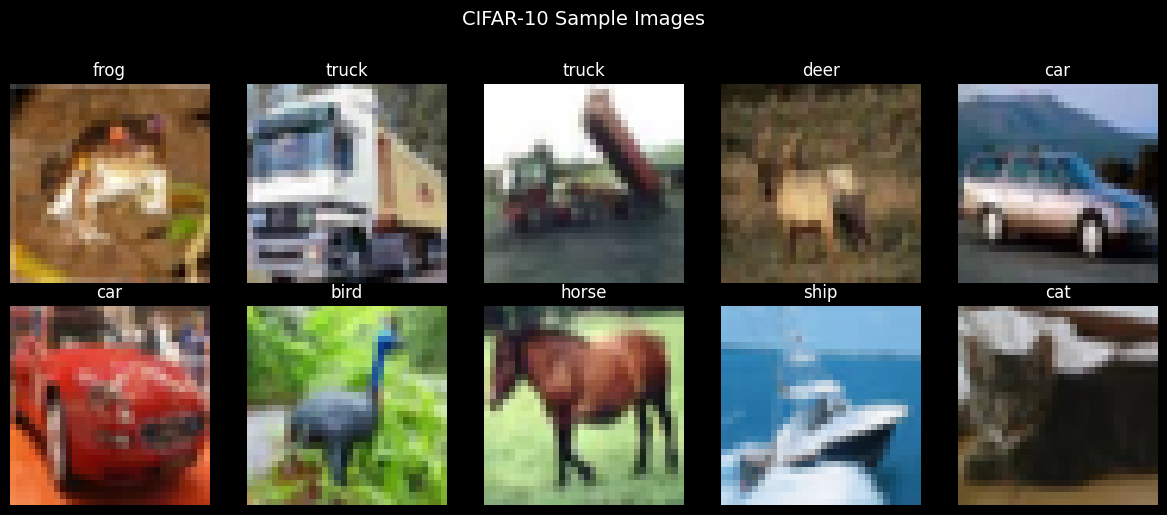

CIFAR-10 loaded and visualized!


In [2]:
# Define transformations
transform_train = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.4914, 0.4822, 0.4465],
                         std=[0.2470, 0.2435, 0.2616])
])

transform_test = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.4914, 0.4822, 0.4465],
                         std=[0.2470, 0.2435, 0.2616])
])

train_dataset = CIFAR10(root=DATA_PATH, train=True, download=False, transform=transform_train)
test_dataset = CIFAR10(root=DATA_PATH, train=False, download=False, transform=transform_test)

# Create dataloaders
train_loader = DataLoader(train_dataset, batch_size=128, shuffle=True, num_workers=NUM_WORKERS)
test_loader = DataLoader(test_dataset, batch_size=128, shuffle=False, num_workers=NUM_WORKERS)

# CIFAR-10 class names
class_names = ['airplane', 'car', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck']

print(f"Training samples: {len(train_dataset)}")
print(f"Test samples: {len(test_dataset)}")
print(f"Train batches: {len(train_loader)}")
print(f"Test batches: {len(test_loader)}")
print(f"\nClasses: {class_names}")

display_dataset = CIFAR10(root=DATA_PATH, train=True, download=False, transform=transforms.ToTensor())

fig, axes = plt.subplots(2, 5, figsize=(12, 5))
fig.suptitle("CIFAR-10 Sample Images", fontsize=14, y=1.02)

for i, ax in enumerate(axes.flat):
    img, label = display_dataset[i]
    img = img.permute(1, 2, 0)  # CHW -> HWC
    ax.imshow(img)
    ax.set_title(f"{class_names[label]}")
    ax.axis('off')

plt.tight_layout()
plt.show()

print("CIFAR-10 loaded and visualized!")

## Step 2: Define Custom CNN Architecture

In [3]:
class CustomCNN(nn.Module):
    """
    Custom CNN for CIFAR-10 Classification
    """

    def __init__(self, num_classes=10):
        super(CustomCNN, self).__init__()

        # Conv Block 1: 3 → 32 channels
        self.conv_block1 = nn.Sequential(
            nn.Conv2d(3, 32, kernel_size=3, padding=1),
            nn.ReLU(inplace=True),
            nn.Conv2d(32, 32, kernel_size=3, padding=1),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(kernel_size=2, stride=2),  # 32x32 → 16x16
            nn.Dropout(0.2)
        )

        # Conv Block 2: 32 → 64 channels
        self.conv_block2 = nn.Sequential(
            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.ReLU(inplace=True),
            nn.Conv2d(64, 64, kernel_size=3, padding=1),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(kernel_size=2, stride=2),  # 16x16 → 8x8
            nn.Dropout(0.3)
        )

        # Conv Block 3: 64 → 128 channels
        self.conv_block3 = nn.Sequential(
            nn.Conv2d(64, 128, kernel_size=3, padding=1),
            nn.ReLU(inplace=True),
            nn.Conv2d(128, 128, kernel_size=3, padding=1),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(kernel_size=2, stride=2),  # 8x8 → 4x4
            nn.Dropout(0.4)
        )

        # Fully Connected Block
        self.fc_block = nn.Sequential(
            nn.Flatten(),
            nn.Linear(128 * 4 * 4, 512),
            nn.ReLU(inplace=True),
            nn.Dropout(0.5),
            nn.Linear(512, num_classes)
        )

    def forward(self, x):
        x = self.conv_block1(x)  # → 16x16x32
        x = self.conv_block2(x)  # → 8x8x64
        x = self.conv_block3(x)  # → 4x4x128
        x = self.fc_block(x)     # → 10 classes
        return x

custom_cnn = CustomCNN(num_classes=10).to(device)

# count parameters
total_params = sum(p.numel() for p in custom_cnn.parameters())
trainable_params = sum(p.numel() for p in custom_cnn.parameters() if p.requires_grad)

print(f"\nCustom CNN Architecture:")
print(custom_cnn)
print(f"\nTotal parameters: {total_params:,}")
print(f"Trainable parameters: {trainable_params:,}")


Custom CNN Architecture:
CustomCNN(
  (conv_block1): Sequential(
    (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU(inplace=True)
    (2): Conv2d(32, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (3): ReLU(inplace=True)
    (4): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (5): Dropout(p=0.2, inplace=False)
  )
  (conv_block2): Sequential(
    (0): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU(inplace=True)
    (2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (3): ReLU(inplace=True)
    (4): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (5): Dropout(p=0.3, inplace=False)
  )
  (conv_block3): Sequential(
    (0): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU(inplace=True)
    (2): Conv2d(128, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (3): ReLU(inplace=True)
  

## Step 3: Train Custom CNN

  Batch [50/391] Loss: 1.7564 Acc: 20.12%
  Batch [100/391] Loss: 1.5733 Acc: 25.85%
  Batch [150/391] Loss: 1.7113 Acc: 29.43%
  Batch [200/391] Loss: 1.5045 Acc: 32.17%
  Batch [250/391] Loss: 1.4565 Acc: 34.34%
  Batch [300/391] Loss: 1.3554 Acc: 36.13%
  Batch [350/391] Loss: 1.4276 Acc: 37.73%

Epoch [1/15]
  Train: Loss=1.6259, Acc=38.82%
  Test: Acc=51.96%
------------------------------------------------------------
  Batch [50/391] Loss: 1.2921 Acc: 50.55%
  Batch [100/391] Loss: 1.2643 Acc: 51.32%
  Batch [150/391] Loss: 1.1248 Acc: 52.22%
  Batch [200/391] Loss: 1.3722 Acc: 52.76%
  Batch [250/391] Loss: 1.2781 Acc: 53.49%
  Batch [300/391] Loss: 1.3657 Acc: 54.10%
  Batch [350/391] Loss: 0.9969 Acc: 54.91%

Epoch [2/15]
  Train: Loss=1.2350, Acc=55.36%
  Test: Acc=63.81%
------------------------------------------------------------
  Batch [50/391] Loss: 1.0368 Acc: 61.59%
  Batch [100/391] Loss: 1.1368 Acc: 61.53%
  Batch [150/391] Loss: 1.0692 Acc: 62.04%
  Batch [200/391] 

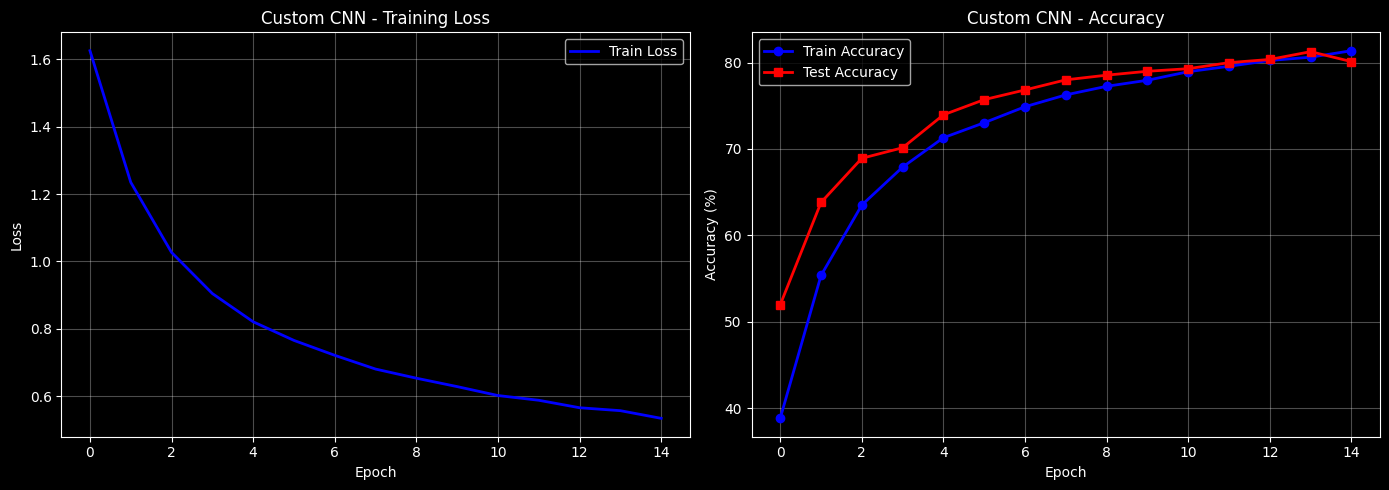

In [4]:
def train_model(model, train_loader, test_loader, epochs=5, lr=0.001):
    """Train CNN and return history"""
    criterion = nn.CrossEntropyLoss()
    optimizer = optim.Adam(model.parameters(), lr=lr)

    train_losses, train_accs, test_accs = [], [], []

    for epoch in range(epochs):
        # training
        model.train()
        running_loss = 0.0
        correct = 0
        total = 0

        for batch_idx, (images, labels) in enumerate(train_loader):
            images, labels = images.to(device), labels.to(device)

            optimizer.zero_grad()
            outputs = model(images)
            loss = criterion(outputs, labels)
            loss.backward()
            optimizer.step()

            running_loss += loss.item()
            _, predicted = outputs.max(1)
            total += labels.size(0)
            correct += predicted.eq(labels).sum().item()

            # show progress every 50 batches
            if (batch_idx + 1) % 50 == 0:
                batch_acc = 100. * correct / total
                print(f"  Batch [{batch_idx+1}/{len(train_loader)}] Loss: {loss.item():.4f} Acc: {batch_acc:.2f}%")

        train_loss = running_loss / len(train_loader)
        train_acc = 100. * correct / total
        train_losses.append(train_loss)
        train_accs.append(train_acc)

        # evaluation
        model.eval()
        correct = 0
        total = 0

        with torch.no_grad():
            for images, labels in test_loader:
                images, labels = images.to(device), labels.to(device)
                outputs = model(images)
                _, predicted = outputs.max(1)
                total += labels.size(0)
                correct += predicted.eq(labels).sum().item()

        test_acc = 100. * correct / total
        test_accs.append(test_acc)

        print(f"\nEpoch [{epoch+1}/{epochs}]")
        print(f"  Train: Loss={train_loss:.4f}, Acc={train_acc:.2f}%")
        print(f"  Test: Acc={test_acc:.2f}%")
        print("-"*60)

    return train_losses, train_accs, test_accs

# train the custom CNN
train_losses, train_accs, test_accs = train_model(
    custom_cnn, train_loader, test_loader, epochs=15, lr=0.001
)

print(f"\nTraining complete!")
print(f"Final Train Accuracy: {train_accs[-1]:.2f}%")
print(f"Final Test Accuracy: {test_accs[-1]:.2f}%")

# plot training history
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

ax1.plot(train_losses, 'b-', linewidth=2, label='Train Loss')
ax1.set_xlabel('Epoch')
ax1.set_ylabel('Loss')
ax1.set_title('Custom CNN - Training Loss')
ax1.legend()
ax1.grid(True, alpha=0.3)

ax2.plot(train_accs, 'b-', linewidth=2, label='Train Accuracy', marker='o')
ax2.plot(test_accs, 'r-', linewidth=2, label='Test Accuracy', marker='s')
ax2.set_xlabel('Epoch')
ax2.set_ylabel('Accuracy (%)')
ax2.set_title('Custom CNN - Accuracy')
ax2.legend()
ax2.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

## Visualize Predictions



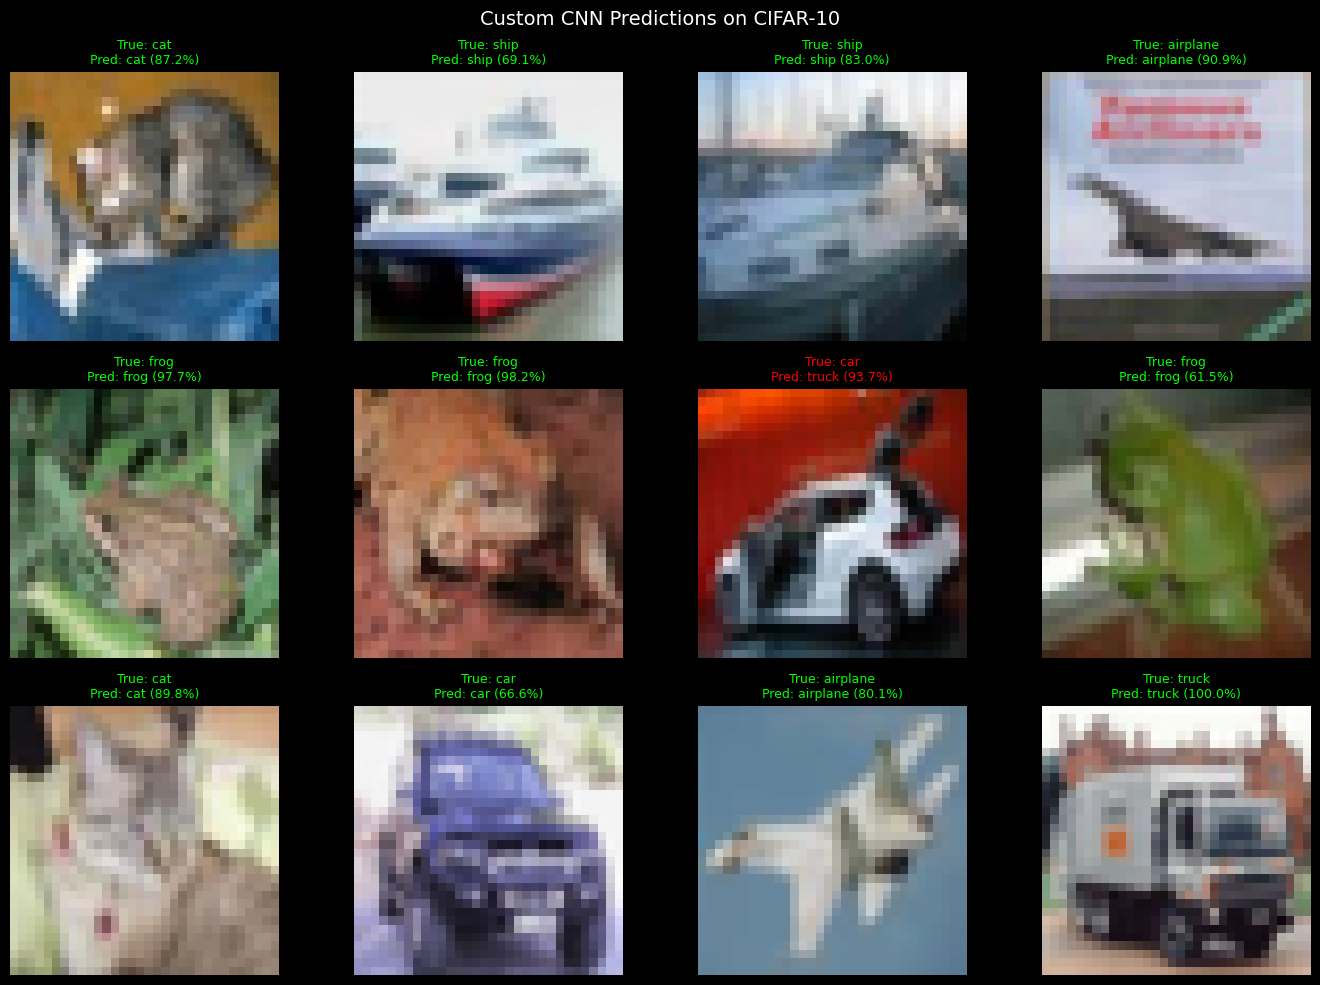


Batch Accuracy: 85.9%
Correct: 110/128


In [5]:
custom_cnn.eval()

dataiter = iter(test_loader)
images, labels = next(dataiter)
images, labels = images.to(device), labels.to(device)

with torch.no_grad():
    outputs = custom_cnn(images)
    _, predicted = outputs.max(1)
    probabilities = torch.softmax(outputs, dim=1)

# denormalize images for display
mean = torch.tensor([0.4914, 0.4822, 0.4465]).view(3, 1, 1).to(device)
std = torch.tensor([0.2470, 0.2435, 0.2616]).view(3, 1, 1).to(device)
images_denorm = images * std + mean

# plot predictions
fig, axes = plt.subplots(3, 4, figsize=(14, 10))
fig.suptitle("Custom CNN Predictions on CIFAR-10", fontsize=14, y=0.98)

for idx, ax in enumerate(axes.flat):
    img = images_denorm[idx].cpu().permute(1, 2, 0).numpy()
    img = np.clip(img, 0, 1)

    true_label = class_names[labels[idx]]
    pred_label = class_names[predicted[idx]]
    confidence = probabilities[idx][predicted[idx]].item() * 100

    ax.imshow(img)

    # color: green if correct, red if wrong
    color = 'lime' if predicted[idx] == labels[idx] else 'red'
    title = f"True: {true_label}\nPred: {pred_label} ({confidence:.1f}%)"
    ax.set_title(title, fontsize=9, color=color)
    ax.axis('off')

plt.tight_layout()
plt.show()

# calculate accuracy on this batch
batch_acc = (predicted == labels).sum().item() / len(labels) * 100
print(f"\nBatch Accuracy: {batch_acc:.1f}%")
print(f"Correct: {(predicted == labels).sum().item()}/{len(labels)}")


# part 2: Transfer Learning on Oxford Pets Dataset



In [6]:
# Load Oxford-IIIT Pet Dataset from Google Drive
from torchvision.datasets import OxfordIIITPet
from torchvision.models import resnet50, ResNet50_Weights

# Define transforms for Oxford Pets (Data Augmentation)
transform_pets_train = transforms.Compose([
    transforms.Resize(256),
    transforms.RandomCrop(224),
    transforms.RandomHorizontalFlip(),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406],
                         std=[0.229, 0.224, 0.225])
])

transform_pets_test = transforms.Compose([
    transforms.Resize(256),
    transforms.CenterCrop(224),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406],
                         std=[0.229, 0.224, 0.225])
])

pets_train = OxfordIIITPet(root=DATA_PATH, split='trainval', download=False, transform=transform_pets_train)
pets_test = OxfordIIITPet(root=DATA_PATH, split='test', download=False, transform=transform_pets_test)

pets_train_loader = DataLoader(pets_train, batch_size=32, shuffle=True, num_workers=NUM_WORKERS)
pets_test_loader = DataLoader(pets_test, batch_size=32, shuffle=False, num_workers=NUM_WORKERS)

print(f"Oxford Pets Dataset loaded from Google Drive!")
print(f"Training samples: {len(pets_train)}")
print(f"Test samples: {len(pets_test)}")
print(f"Number of breeds: 37 (25 dogs + 12 cats)")
print(f"Image size: 224x224 (ResNet requirement)")

Oxford Pets Dataset loaded from Google Drive!
Training samples: 3680
Test samples: 3669
Number of breeds: 37 (25 dogs + 12 cats)
Image size: 224x224 (ResNet requirement)


## Step 2: Visualize Pet Breeds

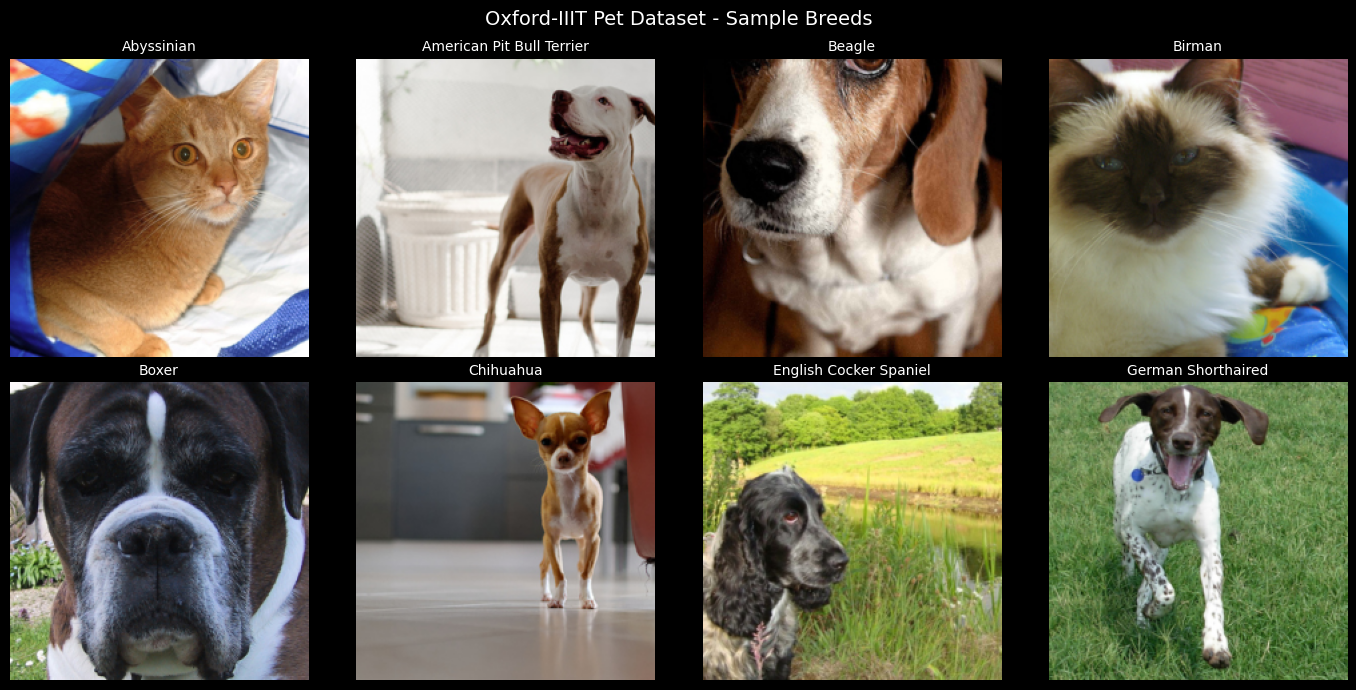

In [7]:
# Visualize some pet images
pets_display = OxfordIIITPet(root=DATA_PATH, split='trainval', download=False,
                             transform=transforms.Compose([
                                 transforms.Resize(256),
                                 transforms.CenterCrop(224),
                                 transforms.ToTensor()
                             ]))

fig, axes = plt.subplots(2, 4, figsize=(14, 7))
fig.suptitle("Oxford-IIIT Pet Dataset - Sample Breeds", fontsize=14, y=0.98)

for i, ax in enumerate(axes.flat):
    img, label = pets_display[i * 100]
    ax.imshow(img.permute(1, 2, 0))
    breed_name = pets_display.classes[label].replace('_', ' ').title()
    ax.set_title(f"{breed_name}", fontsize=10)
    ax.axis('off')

plt.tight_layout()
plt.show()

## Step 3: Load Pre-trained ResNet50




In [8]:
# load pre-trained ResNet50
print("Loading pre-trained ResNet50...")
resnet_model = resnet50(weights=ResNet50_Weights.IMAGENET1K_V2)

print("\nResNet50 loaded!")
print(f"Pre-trained on: ImageNet (1.2M images, 1000 classes)")
print(f"Architecture: 50 layers with residual connections")

# freeze ALL layers
for param in resnet_model.parameters():
    param.requires_grad = False

print("\nFroze all layers")

# replace final FC layer
# ResNet50 has 2048 features before final FC
resnet_model.fc = nn.Linear(2048, 37)  # 37 pet breeds

resnet_model = resnet_model.to(device)

# count parameters
total_params = sum(p.numel() for p in resnet_model.parameters())
trainable_params = sum(p.numel() for p in resnet_model.parameters() if p.requires_grad)

print(f"\nResNet50 Transfer Learning:")
print(f"Total parameters: {total_params:,}")
print(f"Trainable parameters: {trainable_params:,} (only final FC)")
print(f"Frozen parameters: {total_params - trainable_params:,}")
print(f"\nReady to train on Oxford Pets!")

Loading pre-trained ResNet50...
Downloading: "https://download.pytorch.org/models/resnet50-11ad3fa6.pth" to /root/.cache/torch/hub/checkpoints/resnet50-11ad3fa6.pth


100%|██████████| 97.8M/97.8M [00:00<00:00, 210MB/s]



ResNet50 loaded!
Pre-trained on: ImageNet (1.2M images, 1000 classes)
Architecture: 50 layers with residual connections

Froze all layers

ResNet50 Transfer Learning:
Total parameters: 23,583,845
Trainable parameters: 75,813 (only final FC)
Frozen parameters: 23,508,032

Ready to train on Oxford Pets!


## Step 4: Train ResNet50 on Pet Breeds

Training ResNet50 Transfer Learning on Oxford Pets (20 epochs)...
(Only training final FC layer - all other layers frozen)
  Batch [50/115] Loss: 1.8047 Acc: 47.12%
  Batch [100/115] Loss: 1.3835 Acc: 64.28%

Epoch [1/20]
  Train: Loss=1.9366, Acc=66.66%
  Test: Acc=85.06%
------------------------------------------------------------
  Batch [50/115] Loss: 0.6022 Acc: 90.44%
  Batch [100/115] Loss: 0.5850 Acc: 89.78%

Epoch [2/20]
  Train: Loss=0.6692, Acc=89.73%
  Test: Acc=87.11%
------------------------------------------------------------
  Batch [50/115] Loss: 0.2916 Acc: 92.62%
  Batch [100/115] Loss: 0.4035 Acc: 92.41%

Epoch [3/20]
  Train: Loss=0.4262, Acc=92.42%
  Test: Acc=89.83%
------------------------------------------------------------
  Batch [50/115] Loss: 0.5571 Acc: 93.62%
  Batch [100/115] Loss: 0.3094 Acc: 94.06%

Epoch [4/20]
  Train: Loss=0.3208, Acc=94.10%
  Test: Acc=90.19%
------------------------------------------------------------
  Batch [50/115] Loss: 0.2178

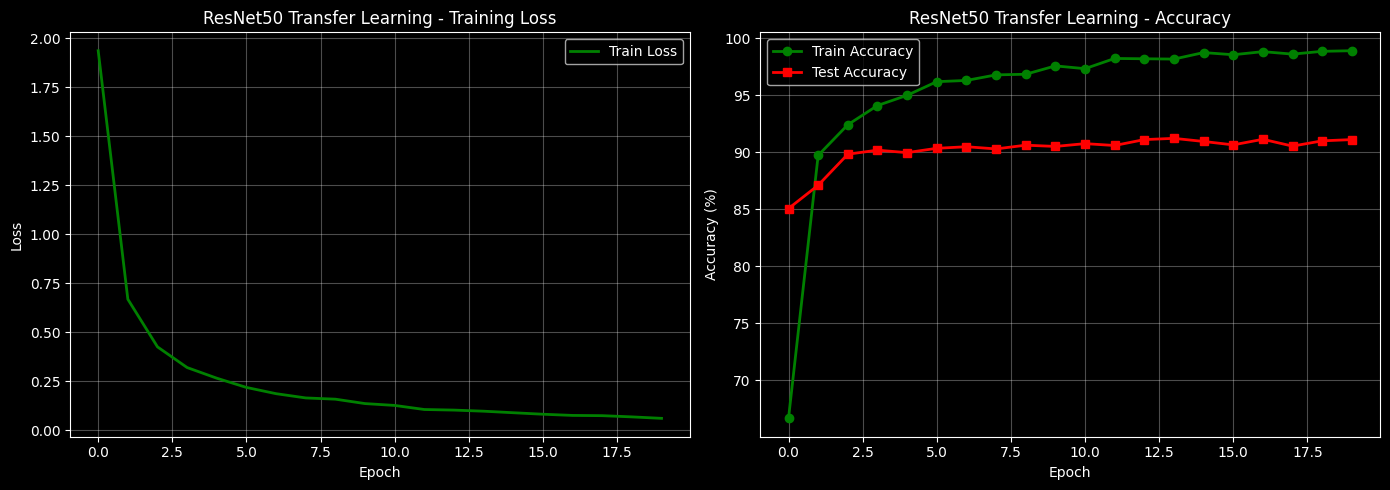

TRANSFER LEARNING RESULTS
ResNet50 (Transfer Learning): 91.11%

Task: Classify 37 pet breeds
Training time: ~5 minutes (20 epochs)
Parameters trained: 75,813 (only final layer)


In [9]:
# train ResNet50 (only final layer)
print("Training ResNet50 Transfer Learning on Oxford Pets (20 epochs)...")
print("(Only training final FC layer - all other layers frozen)")

# use same train_model function from Part 1
resnet_train_losses, resnet_train_accs, resnet_test_accs = train_model(
    resnet_model, pets_train_loader, pets_test_loader, epochs=20, lr=0.001
)

print(f"\nTraining complete!")
print(f"Final Train Accuracy: {resnet_train_accs[-1]:.2f}%")
print(f"Final Test Accuracy: {resnet_test_accs[-1]:.2f}%")
print(f"\nNote: Training only final layer is MUCH faster than training from scratch!")

# plot ResNet50 training history
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

ax1.plot(resnet_train_losses, 'g-', linewidth=2, label='Train Loss')
ax1.set_xlabel('Epoch')
ax1.set_ylabel('Loss')
ax1.set_title('ResNet50 Transfer Learning - Training Loss')
ax1.legend()
ax1.grid(True, alpha=0.3)

ax2.plot(resnet_train_accs, 'g-', linewidth=2, label='Train Accuracy', marker='o')
ax2.plot(resnet_test_accs, 'r-', linewidth=2, label='Test Accuracy', marker='s')
ax2.set_xlabel('Epoch')
ax2.set_ylabel('Accuracy (%)')
ax2.set_title('ResNet50 Transfer Learning - Accuracy')
ax2.legend()
ax2.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

print("TRANSFER LEARNING RESULTS")
print(f"ResNet50 (Transfer Learning): {resnet_test_accs[-1]:.2f}%")
print(f"\nTask: Classify 37 pet breeds")
print(f"Training time: ~5 minutes (20 epochs)")
print(f"Parameters trained: {trainable_params:,} (only final layer)")

## Visualize ResNet Predictions



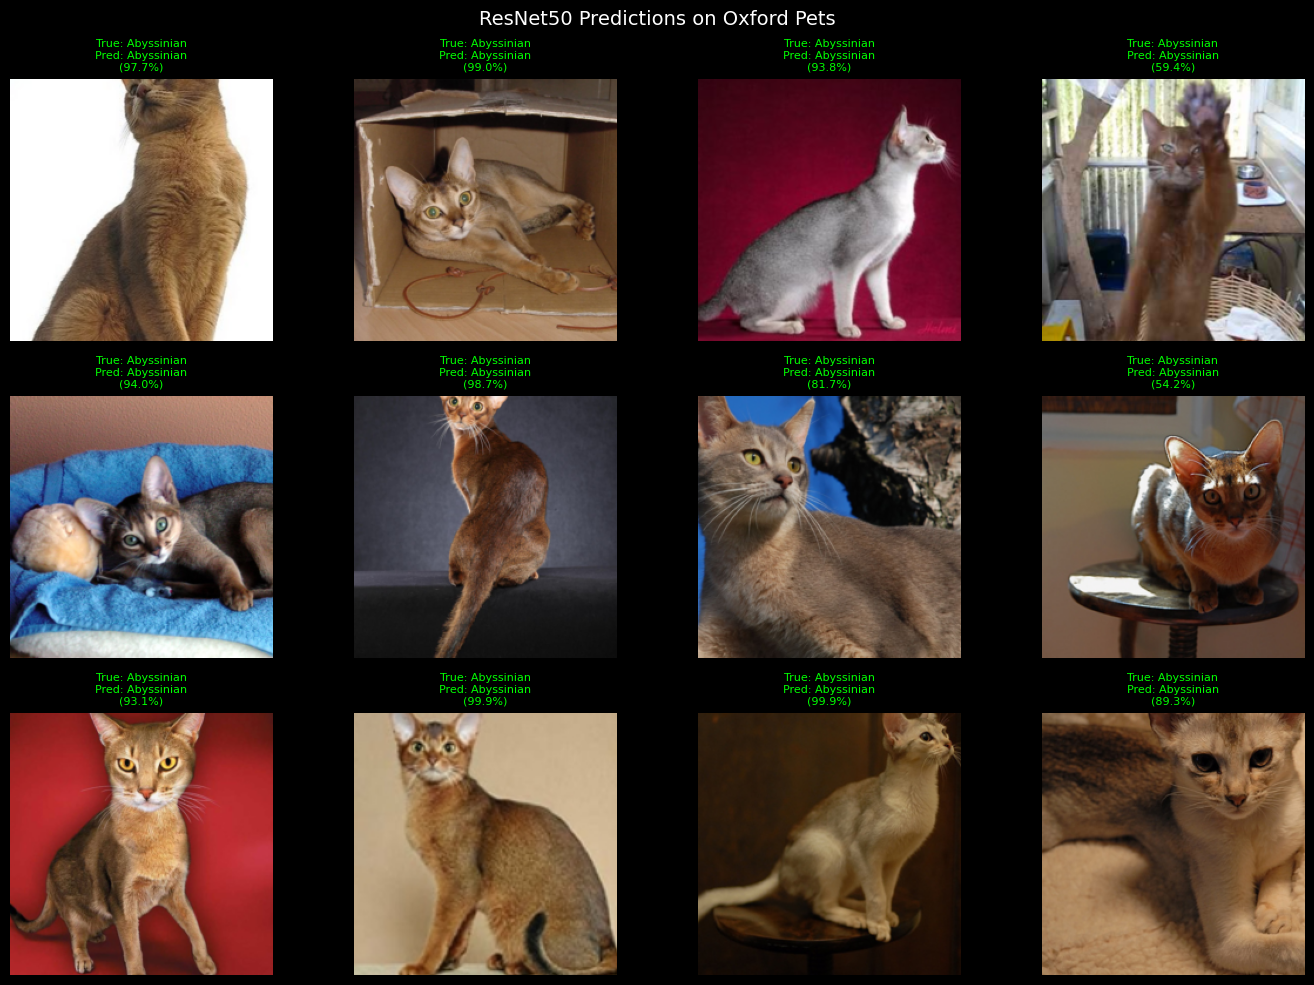


Batch Accuracy: 93.8%
Correct: 30/32

ResNet50 successfully classifies pet breeds!


In [10]:
# visualize ResNet50 predictions on pet breeds
resnet_model.eval()

# get a batch of test images
dataiter = iter(pets_test_loader)
next(dataiter)
images, labels = next(dataiter)
images, labels = images.to(device), labels.to(device)

with torch.no_grad():
    outputs = resnet_model(images)
    _, predicted = outputs.max(1)
    probabilities = torch.softmax(outputs, dim=1)

# denormalize images for display
mean = torch.tensor([0.485, 0.456, 0.406]).view(3, 1, 1).to(device)
std = torch.tensor([0.229, 0.224, 0.225]).view(3, 1, 1).to(device)
images_denorm = images * std + mean

# plot predictions
fig, axes = plt.subplots(3, 4, figsize=(14, 10))
fig.suptitle("ResNet50 Predictions on Oxford Pets", fontsize=14, y=0.98)

for idx, ax in enumerate(axes.flat):
    img = images_denorm[idx].cpu().permute(1, 2, 0).numpy()
    img = np.clip(img, 0, 1)

    true_label = pets_test.classes[labels[idx]].replace('_', ' ').title()
    pred_label = pets_test.classes[predicted[idx]].replace('_', ' ').title()
    confidence = probabilities[idx][predicted[idx]].item() * 100

    ax.imshow(img)

    # color: green if correct, red if wrong
    color = 'lime' if predicted[idx] == labels[idx] else 'red'
    title = f"True: {true_label}\nPred: {pred_label}\n({confidence:.1f}%)"
    ax.set_title(title, fontsize=8, color=color)
    ax.axis('off')

plt.tight_layout()
plt.show()

batch_acc = (predicted == labels).sum().item() / len(labels) * 100
print(f"\nBatch Accuracy: {batch_acc:.1f}%")
print(f"Correct: {(predicted == labels).sum().item()}/{len(labels)}")
print(f"\nResNet50 successfully classifies pet breeds!")



# part 2.5: YOLO Object Detection


In [11]:
from ultralytics import YOLO
import cv2
import glob
import os
from pathlib import Path
import shutil

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings


## Step 2: YOLO Inference on Pre-trained Model



Found pothole dataset at: /content/week11_data/Pothole Dataset
Found 1243 images
Found 1243 image-label pairs

Sample images:
  img-1.jpg
  img-10.jpg
  img-100.jpg
Loading YOLOv8n (pre-trained on COCO)...
YOLOv8n loaded!

Model info:
  Pre-trained on: COCO dataset (80 classes)
  Classes include: person, car, bicycle, dog, cat, etc.
  Does NOT include: pothole (yet!)
Running YOLO inference on 6 pothole images...
Note: Pre-trained model doesn't know 'pothole' class, so may detect other objects



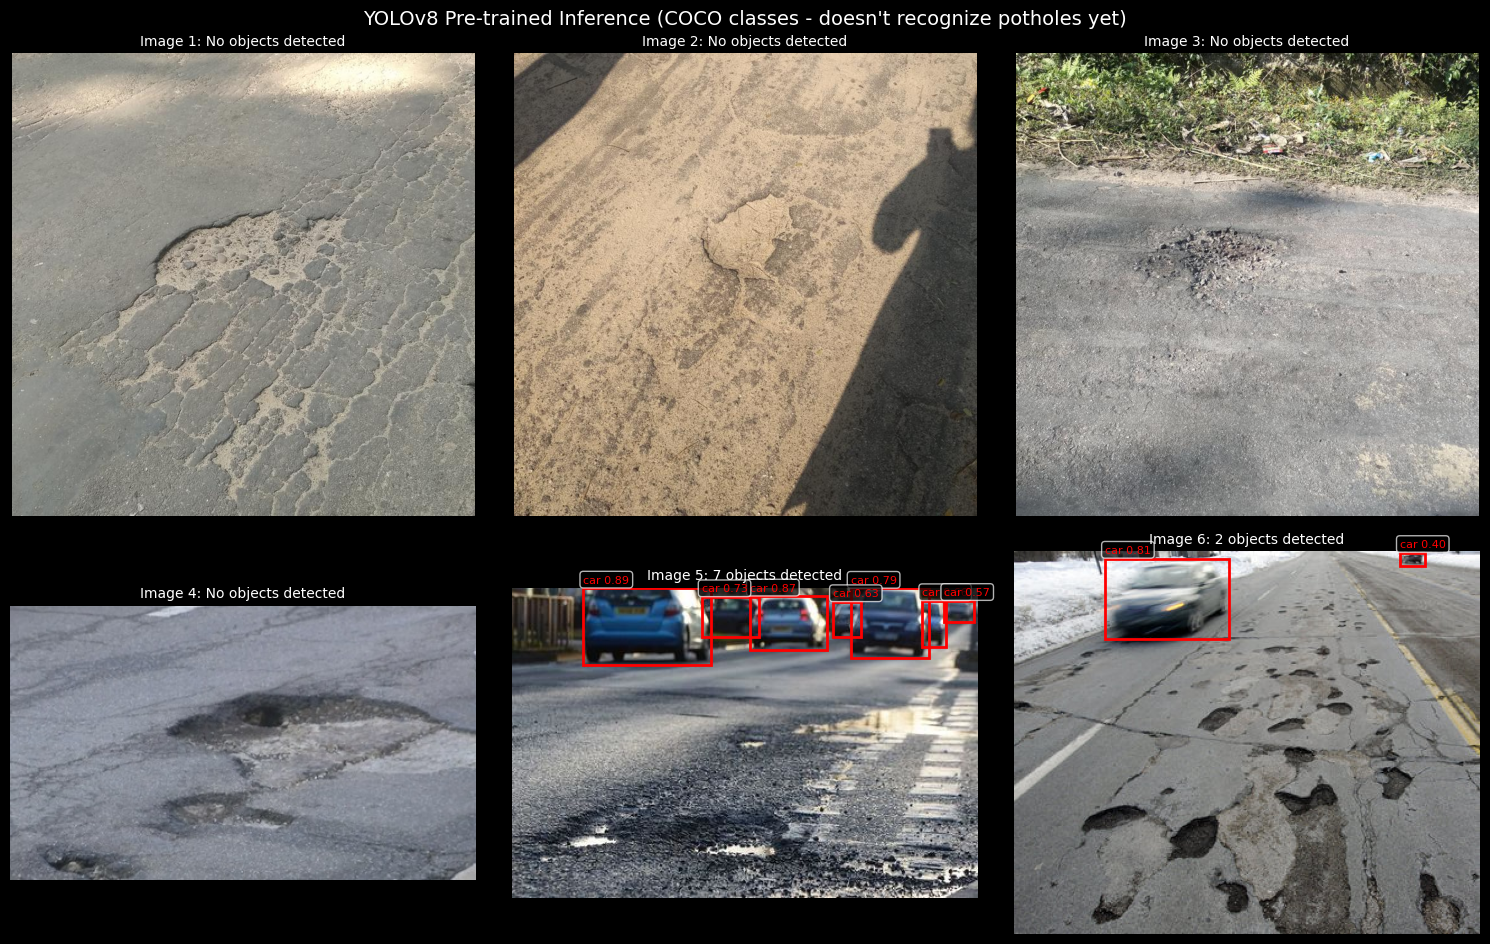

In [12]:
# Check for pothole dataset
import glob

if not os.path.exists(POTHOLE_PATH):
    print(f"ERROR: Pothole Dataset not found at: {POTHOLE_PATH}")
    print("\nMake sure the folder structure is correct in Google Drive:")
    print("  My Drive/week11_data/Pothole Dataset/")
    pothole_images = []
    valid_pairs = []
else:
    print(f"Found pothole dataset at: {POTHOLE_PATH}")

    # Get all pothole images
    pothole_images = sorted(glob.glob(os.path.join(POTHOLE_PATH, "*.jpg")))
    pothole_images = [img for img in pothole_images if "README" not in img.lower()]

    print(f"Found {len(pothole_images)} images")

    # Check for corresponding labels
    pothole_labels = [img.replace('.jpg', '.txt') for img in pothole_images]
    valid_pairs = [(img, lbl) for img, lbl in zip(pothole_images, pothole_labels) if os.path.exists(lbl)]

    print(f"Found {len(valid_pairs)} image-label pairs")

    if len(pothole_images) > 0:
        print(f"\nSample images:")
        for i in range(min(3, len(pothole_images))):
            print(f"  {os.path.basename(pothole_images[i])}")

# Load pre-trained YOLOv8n (trained on COCO dataset)
print("Loading YOLOv8n (pre-trained on COCO)...")

yolo_model = YOLO('yolov8n.pt')

print("YOLOv8n loaded!")
print(f"\nModel info:")
print(f"  Pre-trained on: COCO dataset (80 classes)")
print(f"  Classes include: person, car, bicycle, dog, cat, etc.")
print(f"  Does NOT include: pothole (yet!)")

# Run YOLO inference on pothole images (using pre-trained COCO model)
if len(pothole_images) == 0:
    print("ERROR: No pothole images found!")
    print("Please run the 'check for pothole dataset' cell and ensure the dataset exists on Google Drive.")
else:
    print(f"Running YOLO inference on {min(6, len(pothole_images))} pothole images...")
    print("Note: Pre-trained model doesn't know 'pothole' class, so may detect other objects\n")

    sample_images = pothole_images[:6]
    results = yolo_model.predict(sample_images, conf=0.25, verbose=False)

    fig, axes = plt.subplots(2, 3, figsize=(15, 10))
    fig.suptitle("YOLOv8 Pre-trained Inference (COCO classes - doesn't recognize potholes yet)",
                 fontsize=14, y=0.98)

    for idx, (ax, result) in enumerate(zip(axes.flat, results)):
        img = result.orig_img
        img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

        ax.imshow(img_rgb)

        if len(result.boxes) > 0:
            for box in result.boxes:
                x1, y1, x2, y2 = box.xyxy[0].cpu().numpy()
                conf = box.conf[0].cpu().numpy()
                cls = int(box.cls[0].cpu().numpy())
                label = f"{result.names[cls]} {conf:.2f}"

                rect = plt.Rectangle((x1, y1), x2-x1, y2-y1,
                                      fill=False, edgecolor='red', linewidth=2)
                ax.add_patch(rect)
                ax.text(x1, y1-5, label, color='red', fontsize=8,
                        bbox=dict(boxstyle='round', facecolor='black', alpha=0.7))

            ax.set_title(f"Image {idx+1}: {len(result.boxes)} objects detected", fontsize=10)
        else:
            ax.set_title(f"Image {idx+1}: No objects detected", fontsize=10)

        ax.axis('off')

    plt.tight_layout()
    plt.show()

## Step 3: Fine-tune YOLO on Pothole Dataset



In [13]:
import shutil
import random

if len(pothole_images) == 0:
    print("ERROR: No pothole images found! Run the dataset check cell first.")
else:
    YOLO_DATASET_PATH = "/content/yolo_pothole_dataset"

    os.makedirs(f"{YOLO_DATASET_PATH}/train/images", exist_ok=True)
    os.makedirs(f"{YOLO_DATASET_PATH}/train/labels", exist_ok=True)
    os.makedirs(f"{YOLO_DATASET_PATH}/val/images", exist_ok=True)
    os.makedirs(f"{YOLO_DATASET_PATH}/val/labels", exist_ok=True)

    all_images = pothole_images
    all_labels = [img.replace('.jpg', '.txt') for img in all_images]
    valid_pairs = [(img, lbl) for img, lbl in zip(all_images, all_labels) if os.path.exists(lbl)]

    print(f"Total valid image-label pairs: {len(valid_pairs)}")

    random.seed(42)
    if len(valid_pairs) > 500:
        valid_pairs = random.sample(valid_pairs, 500)
        print(f"Using small subset: {len(valid_pairs)} images (for fast demo)")

    # Split 80/20
    num_train = int(0.8 * len(valid_pairs))
    indices = list(range(len(valid_pairs)))
    random.shuffle(indices)

    train_indices = indices[:num_train]
    val_indices = indices[num_train:]

    print(f"\nDataset split:")
    print(f"  Train samples: {len(train_indices)}")
    print(f"  Val samples: {len(val_indices)}")

    print("\nCopying files to YOLO structure...")
    for idx in train_indices:
        img_src, lbl_src = valid_pairs[idx]
        img_name = os.path.basename(img_src)
        lbl_name = os.path.basename(lbl_src)

        shutil.copy(img_src, f"{YOLO_DATASET_PATH}/train/images/{img_name}")
        shutil.copy(lbl_src, f"{YOLO_DATASET_PATH}/train/labels/{lbl_name}")

    for idx in val_indices:
        img_src, lbl_src = valid_pairs[idx]
        img_name = os.path.basename(img_src)
        lbl_name = os.path.basename(lbl_src)

        shutil.copy(img_src, f"{YOLO_DATASET_PATH}/val/images/{img_name}")
        shutil.copy(lbl_src, f"{YOLO_DATASET_PATH}/val/labels/{lbl_name}")

    # Create data.yaml config file
    yaml_content = f"""
    path: {YOLO_DATASET_PATH}
    train: {YOLO_DATASET_PATH}/train/images
    val: {YOLO_DATASET_PATH}/val/images

    nc: 1
    names: ['pothole']
    """

    with open(f"{YOLO_DATASET_PATH}/data.yaml", 'w') as f:
      f.write(yaml_content)

    print(f"Dataset prepared!")
    print(f"Config: {YOLO_DATASET_PATH}/data.yaml")
    print(f"\nNote: Using local Colab storage for faster training")

print("Fine-tuning YOLOv8n on pothole dataset...")
print("Settings for quick demonstration:")
print("  - Epochs: 3")
print("  - Image size: 320 (small resolution)")
print("  - Batch size: 32")
print("  - Dataset: 100 images")
print("\nExpected time: ~2-3 minutes on Colab GPU")

yolo_finetune = YOLO('yolov8n.pt')

results_train = yolo_finetune.train(
    data=f"{YOLO_DATASET_PATH}/data.yaml",
    epochs=20,
    imgsz=640,       # standard YOLO size for good detail detection, we could make that smaller for faster execution
    batch=16,
    name='pothole_yolo',
    patience=5,
    save=True,
    plots=True,      # turn on plots to see the results.png in the runs folder
    verbose=True,
    device=0 if torch.cuda.is_available() else 'cpu'
)

weights_path = str(yolo_finetune.trainer.best)

print("\nFine-tuning complete!")
print(f"Model saved to: {weights_path}")

globals()['YOLO_MODEL_PATH'] = weights_path

if os.path.exists(weights_path):
    print(f"Model file verified: {os.path.getsize(weights_path) / (1024*1024):.1f} MB")

Total valid image-label pairs: 1243
Using small subset: 500 images (for fast demo)

Dataset split:
  Train samples: 400
  Val samples: 100

Copying files to YOLO structure...
Dataset prepared!
Config: /content/yolo_pothole_dataset/data.yaml

Note: Using local Colab storage for faster training
Fine-tuning YOLOv8n on pothole dataset...
Settings for quick demonstration:
  - Epochs: 3
  - Image size: 320 (small resolution)
  - Batch size: 32
  - Dataset: 100 images

Expected time: ~2-3 minutes on Colab GPU
Ultralytics 8.4.201 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (NVIDIA RTX PRO 6000 Blackwell Server Edition, 97250MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/yolo_pothole_dataset/data.yaml,

## Step 4: Evaluate Fine-tuned YOLO



Loading fine-tuned YOLO model...
path is: /content/runs/detect/pothole_yolo/weights/best.pt

Evaluating on validation set...
Ultralytics 8.4.201 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (NVIDIA RTX PRO 6000 Blackwell Server Edition, 97250MiB)
Model summary (fused): 73 layers, 3,132,707 parameters, 0 gradients, 8.6 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 8505.4±7737.0 MB/s, size: 489.7 KB)
val: Scanning /content/yolo_pothole_dataset/val/labels.cache... 100 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 100/100 52.4Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 7/7 13.2it/s 0.5s
                   all        100        349      0.575      0.523      0.556      0.265
Speed: 0.3ms preprocess, 1.9ms inference, 0.0ms loss, 0.4ms postprocess per image
Results saved to /content/runs/detect/val

FINE-TUNED YOLO METRICS ON POTHOLE DETECTION
mAP50: 0.5563
mAP50-95: 0.2646
Precision: 0.5746
Recall: 0.52

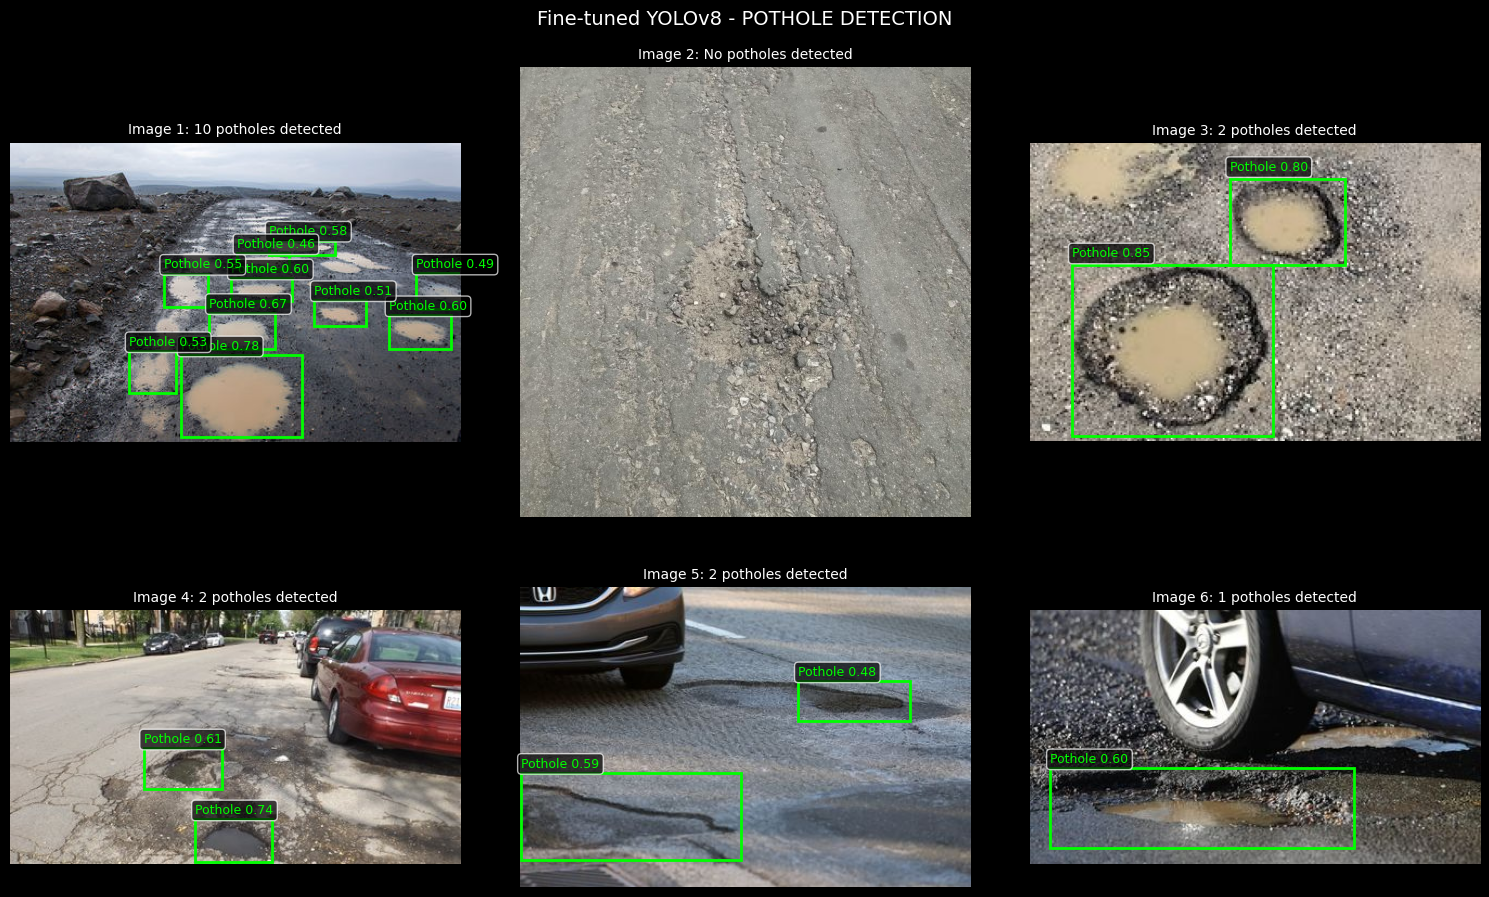


SUCCESS! Fine-tuned YOLO detects potholes!

Comparison:
  Pre-trained YOLO: Detects common objects (person, car, etc.)
  Fine-tuned YOLO: Detects POTHOLES specifically!


In [14]:
import glob

YOLO_MODEL_PATH = globals().get('YOLO_MODEL_PATH', None)

if YOLO_MODEL_PATH is None or not os.path.exists(YOLO_MODEL_PATH):
    possible_paths = glob.glob('/content/runs/detect/pothole_yolo/weights/best.pt')
    if possible_paths:
        YOLO_MODEL_PATH = sorted(possible_paths)[-1]  # Get the latest
        print(f"Found model at: {YOLO_MODEL_PATH}")
    else:
        print("ERROR: Fine-tuned model not found!")
        print("Please run the training cell first.")
        YOLO_MODEL_PATH = None

if YOLO_MODEL_PATH and os.path.exists(YOLO_MODEL_PATH):
    print("Loading fine-tuned YOLO model...")
    yolo_finetuned = YOLO(YOLO_MODEL_PATH)

    print("path is: "+ YOLO_MODEL_PATH)
    print("\nEvaluating on validation set...")
    metrics = yolo_finetuned.val(data=f"{YOLO_DATASET_PATH}/data.yaml", verbose=False)

    print("\nFINE-TUNED YOLO METRICS ON POTHOLE DETECTION")
    print(f"mAP50: {metrics.box.map50:.4f}")
    print(f"mAP50-95: {metrics.box.map:.4f}")
    print(f"Precision: {metrics.box.mp:.4f}")
    print(f"Recall: {metrics.box.mr:.4f}")

    val_images_list = sorted(glob.glob(f"{YOLO_DATASET_PATH}/val/images/*.jpg"))[:6]

    if len(val_images_list) == 0:
        val_images_list = pothole_images[:6]

    print(f"\nTesting on {len(val_images_list)} images...")
    results_finetuned = yolo_finetuned.predict(val_images_list, conf=0.40, verbose=False)

    fig, axes = plt.subplots(2, 3, figsize=(15, 10))
    fig.suptitle("Fine-tuned YOLOv8 - POTHOLE DETECTION", fontsize=14, y=0.98)

    for idx, (ax, result) in enumerate(zip(axes.flat, results_finetuned)):
        img = result.orig_img
        img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

        ax.imshow(img_rgb)

        if len(result.boxes) > 0:
            for box in result.boxes:
                x1, y1, x2, y2 = box.xyxy[0].cpu().numpy()
                conf = box.conf[0].cpu().numpy()
                label = f"Pothole {conf:.2f}"

                rect = plt.Rectangle((x1, y1), x2-x1, y2-y1,
                                      fill=False, edgecolor='lime', linewidth=2)
                ax.add_patch(rect)
                ax.text(x1, y1-5, label, color='lime', fontsize=9,
                        bbox=dict(boxstyle='round', facecolor='black', alpha=0.7))

            ax.set_title(f"Image {idx+1}: {len(result.boxes)} potholes detected", fontsize=10)
        else:
            ax.set_title(f"Image {idx+1}: No potholes detected", fontsize=10)

        ax.axis('off')

    plt.tight_layout()
    plt.show()

    print("\nSUCCESS! Fine-tuned YOLO detects potholes!")
    print("\nComparison:")
    print("  Pre-trained YOLO: Detects common objects (person, car, etc.)")
    print("  Fine-tuned YOLO: Detects POTHOLES specifically!")



# part 3: Practice Exercises


In [15]:
class DeeperCNN(nn.Module):
    """Deeper CNN with 4 convolutional blocks"""

    def __init__(self, num_classes=10):
        super(DeeperCNN, self).__init__()
        self.conv_block1 = nn.Sequential(
            nn.Conv2d(3, 32, kernel_size=3, padding=1),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(kernel_size=2, stride=2),
            nn.Dropout(0.2)
        )
        self.conv_block2 = nn.Sequential(
            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(kernel_size=2, stride=2),
            nn.Dropout(0.3)
        )

        self.conv_block3 = nn.Sequential(
            nn.Conv2d(64, 128, kernel_size=3, padding=1),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(kernel_size=2, stride=2),
            nn.Dropout(0.4)
        )

        self.conv_block4 = nn.Sequential(
            nn.Conv2d(128, 256, kernel_size=3, padding=1),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(kernel_size=2, stride=2),
            nn.Dropout(0.4)
        )

        self.fc_block = nn.Sequential(
            nn.Flatten(),
            nn.Linear(256 * 2 * 2, 512),
            nn.ReLU(inplace=True),
            nn.Dropout(0.5),
            nn.Linear(512, num_classes)
        )

    def forward(self, x):
        x = self.conv_block1(x)
        x = self.conv_block2(x)
        x = self.conv_block3(x)
        x = self.conv_block4(x)
        x = self.fc_block(x)
        return x

# test your model
deeper_cnn = DeeperCNN(num_classes=10).to(device)
test_input = torch.randn(1, 3, 32, 32).to(device)
test_output = deeper_cnn(test_input)

print(f"Model created successfully!")
print(f"Input shape: {test_input.shape}")
print(f"Output shape: {test_output.shape}")
print(f"Parameters: {sum(p.numel() for p in deeper_cnn.parameters()):,}")



Model created successfully!
Input shape: torch.Size([1, 3, 32, 32])
Output shape: torch.Size([1, 10])
Parameters: 918,346
Visible test passed! Hidden tests will run during grading.


## Exercise 2: Transfer Learning with ResNet18



In [16]:
from torchvision.models import resnet18, ResNet18_Weights

resnet = resnet18(weights=ResNet18_Weights.IMAGENET1K_V1)
for param in resnet.parameters():
    param.requires_grad = False
resnet.fc = nn.Linear(512, 10)
resnet = resnet.to(device)

print("ResNet18 loaded and adapted for CIFAR-10!")

resnet_losses, resnet_train_accs, resnet_test_accs = train_model(
    resnet, train_loader, test_loader, epochs=3, lr=0.001
)


Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 196MB/s]

ResNet18 loaded and adapted for CIFAR-10!


  Batch [50/391] Loss: 1.9904 Acc: 23.52%
  Batch [100/391] Loss: 1.6687 Acc: 29.91%
  Batch [150/391] Loss: 1.6429 Acc: 33.25%
  Batch [200/391] Loss: 1.7194 Acc: 35.48%
  Batch [250/391] Loss: 1.8967 Acc: 36.56%
  Batch [300/391] Loss: 1.7253 Acc: 37.48%
  Batch [350/391] Loss: 1.5435 Acc: 38.27%

Epoch [1/3]
  Train: Loss=1.7651, Acc=38.70%
  Test: Acc=43.12%
------------------------------------------------------------
  Batch [50/391] Loss: 1.6580 Acc: 44.52%
  Batch [100/391] Loss: 1.5324 Acc: 44.45%
  Batch [150/391] Loss: 1.5750 Acc: 44.58%
  Batch [200/391] Loss: 1.5702 Acc: 44.59%
  Batch [250/391] Loss: 1.6419 Acc: 44.59%
  Batch [300/391] Loss: 1.4347 Acc: 44.71%
  Batch [350/391] Loss: 1.5740 Acc: 44.77%

Epoch [2/3]
  Train: Loss=1.5883, Acc=44.75%
  Test: Acc=44.22%
------------------------------------------------------------
  Batch [50/391] Loss: 1.4997 Acc: 45.25%
  Batch [100/391] Loss: 1.5131 Acc: 45.30%
  Batch [150/391] Loss: 1.5452 Acc: 45.28%
  Batch [200/391] Lo

## Exercise 3: Experiment with Data Augmentation



In [17]:

transform_augmented = transforms.Compose([
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomCrop(32, padding=4),
    transforms.ColorJitter(brightness=0.2, contrast=0.2),
    transforms.RandomRotation(degrees=15),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.4914, 0.4822, 0.4465],
                         std=[0.2470, 0.2435, 0.2616])
])
augmented_train_dataset = CIFAR10(
    root=DATA_PATH, train=True, download=False, transform=transform_augmented
)
augmented_train_loader = DataLoader(
    augmented_train_dataset, batch_size=128, shuffle=True, num_workers=NUM_WORKERS
)
augmented_test_dataset = CIFAR10(
    root=DATA_PATH, train=False, download=False, transform=transform_test
)
augmented_test_loader = DataLoader(
    augmented_test_dataset, batch_size=128, shuffle=False, num_workers=NUM_WORKERS
)
deeper_cnn_aug = DeeperCNN(num_classes=10).to(device)

aug_losses, aug_train_accs, aug_test_accs = train_model(
    deeper_cnn_aug, augmented_train_loader, augmented_test_loader,
    epochs=3, lr=0.001
)


  Batch [50/391] Loss: 2.0392 Acc: 17.19%
  Batch [100/391] Loss: 1.8745 Acc: 20.41%
  Batch [150/391] Loss: 1.9060 Acc: 24.09%
  Batch [200/391] Loss: 1.7014 Acc: 26.75%
  Batch [250/391] Loss: 1.6230 Acc: 28.73%
  Batch [300/391] Loss: 1.5732 Acc: 30.36%
  Batch [350/391] Loss: 1.6862 Acc: 31.75%

Epoch [1/3]
  Train: Loss=1.7945, Acc=32.76%
  Test: Acc=48.30%
------------------------------------------------------------
  Batch [50/391] Loss: 1.5035 Acc: 42.98%
  Batch [100/391] Loss: 1.6471 Acc: 42.73%
  Batch [150/391] Loss: 1.5382 Acc: 43.38%
  Batch [200/391] Loss: 1.4071 Acc: 43.90%
  Batch [250/391] Loss: 1.2976 Acc: 44.43%
  Batch [300/391] Loss: 1.5829 Acc: 45.02%
  Batch [350/391] Loss: 1.3067 Acc: 45.35%

Epoch [2/3]
  Train: Loss=1.4872, Acc=45.59%
  Test: Acc=55.94%
------------------------------------------------------------
  Batch [50/391] Loss: 1.4783 Acc: 48.36%
  Batch [100/391] Loss: 1.3314 Acc: 48.25%
  Batch [150/391] Loss: 1.4934 Acc: 48.64%
  Batch [200/391] Lo